# Backtest: buy the top 15 predicted stocks every day (2026 out-of-sample)

This notebook turns each model's predictions into money: **if I had followed this model in 2026, how much would I have made or lost?**

**What the models output.** For every stock and every trading day, each model predicts the stock's return for the *next* trading day,
as a log return (`y_pred`). For daily moves a log return is almost the same as a % return: `0.0123` ≈ **+1.24%**
(exactly: `exp(0.0123) − 1`). `y_true` is the return that really happened.

| Model | How it makes its prediction |
|---|---|
| Transformer | the trained network, looking at the stock's last 60 days |
| ARIMA | a classic time-series formula fit to each stock's own past returns |
| Random guess | a random number, so its "top 15" is just 15 random stocks |

**The strategy (same for every model):**
1. At the close of day *t*, rank all tradable stocks by their predicted return for day *t+1*.
2. Buy the top 15 with equal money in each (1/15 of the portfolio).
3. At the close of day *t+1*, sell them and buy the new top 15. If a stock is in the top 15 again, simply keep it (no trade, no cost).
4. Repeat every trading day from Jan 2 to the latest day of 2026.

**Assumptions**
- Trades happen at the closing price. Prices are adjusted, so dividends are included.
- Trading cost `COST_BPS` per buy and per sell (default 0.10%). Set it to 0 to see results before costs.
- **Tradable stocks only:** on the decision day the stock must cost ≥ \$5 and trade ≥ \$1M per day (20-day median).
  This uses only information known at the time of the trade. It mirrors what a real investor can buy, and it
  removes penny stocks whose Yahoo data has obvious errors (for example NFE jumping between \$0.33 and \$17).
- Benchmark: **All stocks (equal weight)**, the same amount in every tradable stock each day, i.e. "the market" with no model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import config

TOP_N = 15            # stocks bought each day
COST_BPS = 10         # trading cost per buy and per sell, in basis points (10 bps = 0.10%); 0 = no costs
MIN_PRICE = 5.0       # tradable: closing price >= $5 on the decision day ...
MIN_DOLLAR_VOL = 1e6  # ... and 20-day median dollar volume >= $1M
N_RANDOM = 1000       # simulated random-pick portfolios for the significance test
SEED = 0

MODELS = {"Transformer": "transformer", "ARIMA": "arima", "Random guess": "random"}
MARKET = "All stocks (equal weight)"
COLORS = {"Transformer": "#2a78d6", "ARIMA": "#eb6834", "Random guess": "#1baf7a", MARKET: "#8a8a85"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. The predictions
A few rows of the transformer's predictions, with the log returns converted to %.

In [2]:
preds = {name: pd.read_parquet(config.OUT_DIR / f"preds_{f}.parquet") for name, f in MODELS.items()}

sample = preds["Transformer"].head(5).copy()
sample["predicted next-day return %"] = 100 * np.expm1(sample["y_pred"])
sample["actual next-day return %"] = 100 * np.expm1(sample["y_true"])
sample

,date,ticker,y_true,y_pred,predicted next-day return %,actual next-day return %
0,2026-01-02,AAL,0.01,-0.00,-0.18,0.98
1,2026-01-05,AAL,0.02,-0.00,-0.18,2.26
2,2026-01-06,AAL,-0.01,-0.00,-0.25,-1.01
3,2026-01-07,AAL,0.02,-0.00,-0.08,2.04
4,2026-01-08,AAL,-0.02,-0.00,-0.20,-1.63


## 2. Which stocks can be bought each day
`date` in the prediction files is the day being predicted (the day we hold the stock).
The filter uses the price and volume known at the previous close, when the stocks are picked.

In [3]:
calendar = pd.to_datetime(np.load(config.PROC_DIR / "dates.npy"))
prices = pd.read_parquet(config.RAW_DIR / "prices.parquet")
prices["date"] = pd.to_datetime(prices["date"]).dt.normalize()
close = prices.pivot(index="date", columns="ticker", values="close").reindex(calendar)
volume = prices.pivot(index="date", columns="ticker", values="volume").reindex(calendar)
dollar_vol = (close * volume).rolling(20, min_periods=15).median()

# shift(1): the value known at the decision-day close, indexed by the day being predicted
known = pd.DataFrame({"price": close.shift(1).stack(), "dollar_vol": dollar_vol.shift(1).stack()})
known.index.names = ["date", "ticker"]
known = known.reset_index()
known["date"] = known["date"].dt.strftime("%Y-%m-%d")
known["tradable"] = (known["price"] >= MIN_PRICE) & (known["dollar_vol"] >= MIN_DOLLAR_VOL)

for name in preds:
    df = preds[name].merge(known[["date", "ticker", "tradable"]], on=["date", "ticker"], how="left")
    df["tradable"] = df["tradable"].fillna(False).astype(bool)
    df["ret"] = np.expm1(df["y_true"])  # simple return of holding the stock that day
    preds[name] = df

t = preds["Transformer"]
print(f"{t['date'].nunique()} trading days ({t['date'].min()} -> {t['date'].max()}), {t['ticker'].nunique()} stocks; "
      f"on average {t.groupby('date')['tradable'].sum().mean():.0f} are tradable each day")

204 trading days (2026-01-02 -> 2026-10-23), 1623 stocks; on average 1207 are tradable each day


## 3. Run the strategy

In [4]:
def pick_top(df: pd.DataFrame, top_n: int = TOP_N) -> pd.DataFrame:
    # the top_n tradable stocks by predicted return, for every day
    return df[df["tradable"]].sort_values("y_pred", ascending=False).groupby("date").head(top_n)


def backtest(df: pd.DataFrame, top_n: int = TOP_N, cost_bps: float = COST_BPS) -> pd.DataFrame:
    # one row per day: portfolio return before / after costs and the share of the portfolio replaced
    daily = pick_top(df, top_n).groupby("date").agg(gross=("ret", "mean"), names=("ticker", frozenset))
    prev = daily["names"].shift(1)
    daily["turnover"] = [len(n - p) / top_n if isinstance(p, frozenset) else 1.0
                         for n, p in zip(daily["names"], prev)]
    daily["net"] = daily["gross"] - daily["turnover"] * 2 * cost_bps / 1e4  # each replaced name: one sell + one buy
    daily.index = pd.to_datetime(daily.index)
    return daily


results = {name: backtest(df) for name, df in preds.items()}
returns = pd.DataFrame({name: r["net"] for name, r in results.items()})
market = t[t["tradable"]].groupby("date")["ret"].mean()
returns[MARKET] = market.set_axis(pd.to_datetime(market.index))

In [5]:
def summary(r: pd.Series) -> dict:
    growth = (1 + r).cumprod()
    return {
        "$10,000 becomes": 10_000 * growth.iloc[-1],
        "total return %": 100 * (growth.iloc[-1] - 1),
        "annualized return %": 100 * (growth.iloc[-1] ** (252 / len(r)) - 1),
        "annualized volatility %": 100 * r.std() * np.sqrt(252),
        "Sharpe ratio": r.mean() / r.std() * np.sqrt(252),
        "max drawdown %": 100 * (growth / growth.cummax() - 1).min(),
        "winning days %": 100 * (r > 0).mean(),
        "average day %": 100 * r.mean(),
        "best day %": 100 * r.max(),
        "worst day %": 100 * r.min(),
    }


table = pd.DataFrame({name: summary(returns[name]) for name in returns}).T
table["total return before costs %"] = [100 * ((1 + results[n]["gross"]).prod() - 1) if n in results else np.nan
                                        for n in table.index]
table["avg share of portfolio replaced daily %"] = [100 * results[n]["turnover"].mean() if n in results else np.nan
                                                    for n in table.index]
print(f"Top {TOP_N} stocks per day, {COST_BPS} bps cost per buy and per sell (the market line has no costs)")
table

Top 15 stocks per day, 10 bps cost per buy and per sell (the market line has no costs)


,"$10,000 becomes",total return %,annualized return %,annualized volatility %,Sharpe ratio,max drawdown %,winning days %,average day %,best day %,worst day %,total return before costs %,avg share of portfolio replaced daily %
Transformer,"4,489.44",-55.11,-62.82,34.66,-2.68,-56.22,41.18,-0.37,10.72,-6.19,-34.33,92.91
ARIMA,"10,198.71",1.99,2.46,44.97,0.28,-47.15,51.47,0.05,10.09,-5.80,38.45,74.93
Random guess,"8,566.18",-14.34,-17.40,22.91,-0.72,-18.02,48.04,-0.07,4.23,-3.40,28.21,98.86
All stocks (equal weight),"11,325.11",13.25,16.62,17.60,0.96,-11.66,53.43,0.07,3.54,-2.87,NaN,NaN


**How to read the table**
- **Sharpe ratio**: return per unit of risk, per year. Around 1 is good for a real strategy; below 0 means it lost money.
- **Max drawdown**: the worst fall from a previous high, i.e. the most painful stretch you would have lived through.
- **Avg share of portfolio replaced daily**: how much is traded each day. More trading means more costs.

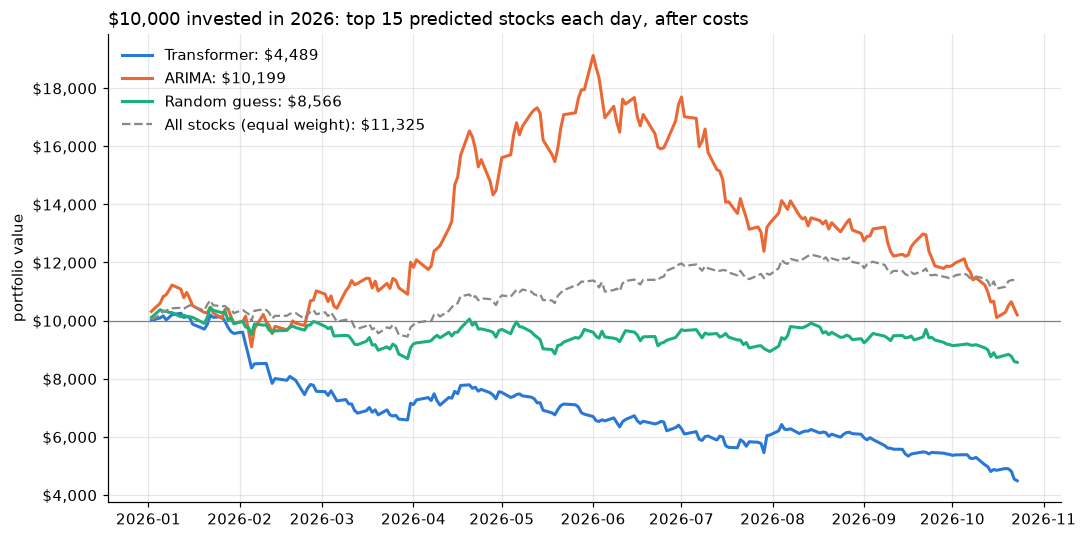

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in returns:
    growth = 10_000 * (1 + returns[name]).cumprod()
    is_model = name in results
    ax.plot(growth.index, growth, color=COLORS[name], lw=2 if is_model else 1.5, ls="-" if is_model else "--",
            label=f"{name}: ${growth.iloc[-1]:,.0f}")
ax.axhline(10_000, color="gray", lw=0.8)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.set_title(f"$10,000 invested in 2026: top {TOP_N} predicted stocks each day, after costs", loc="left")
ax.set_ylabel("portfolio value")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()

## 4. Histogram of daily results
Each bar counts the days on which the portfolio returned that much. The black line is the average day.
A useful strategy shifts the whole histogram to the right, not just a few lucky days.

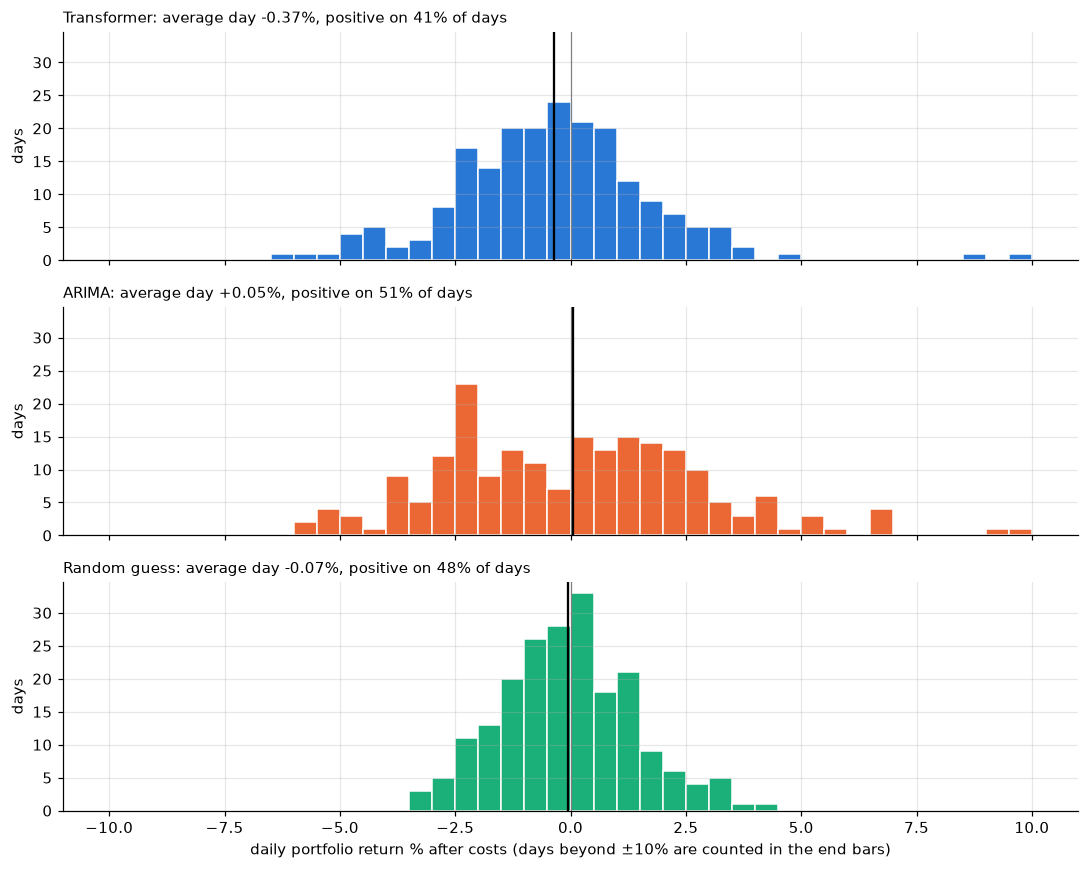

In [7]:
bins = np.arange(-10, 10.5, 0.5)
fig, axes = plt.subplots(len(results), 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, name in zip(axes, results):
    r = returns[name]
    ax.hist(100 * r.clip(-0.1, 0.1), bins=bins, color=COLORS[name], edgecolor="white", linewidth=1)
    ax.axvline(0, color="gray", lw=0.8)
    ax.axvline(100 * r.mean(), color="black", lw=1.5)
    ax.set_title(f"{name}: average day {100 * r.mean():+.2f}%, positive on {100 * (r > 0).mean():.0f}% of days",
                 loc="left", fontsize=10)
    ax.set_ylabel("days")
axes[-1].set_xlabel("daily portfolio return % after costs (days beyond ±10% are counted in the end bars)")
fig.tight_layout()

## 5. Is a model better than luck? Compare with 1,000 random portfolios
One random-guess run can be lucky or unlucky. Here the random strategy is repeated many times
(each day: 15 random tradable stocks, with the same costs). If the transformer really picks better stocks, its result
should land in the right tail of this histogram. **"Random portfolios that did as well or better"** works like a p-value:
below 5% means the result is unlikely to be luck.

,total return %,random portfolios that did as well or better %
strategy,,
Transformer,-55.11,100.00
ARIMA,1.99,1.40
All stocks (equal weight),13.25,0.20


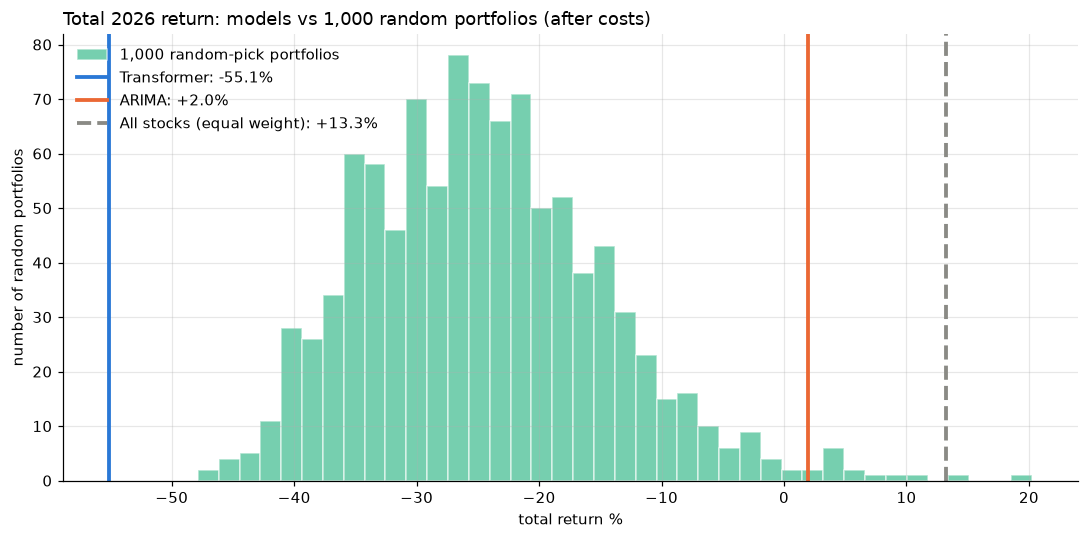

In [8]:
rng = np.random.default_rng(SEED)
day_returns = [g["ret"].to_numpy() for _, g in t[t["tradable"]].groupby("date")]
sim_daily = np.empty((N_RANDOM, len(day_returns)))
for j, r in enumerate(day_returns):
    pick = np.argpartition(rng.random((N_RANDOM, len(r))), TOP_N, axis=1)[:, :TOP_N]
    sim_daily[:, j] = r[pick].mean(axis=1) - 2 * COST_BPS / 1e4  # random picks replace nearly every name daily
sim_total = 100 * (np.prod(1 + sim_daily, axis=1) - 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sim_total, bins=40, color=COLORS["Random guess"], alpha=0.6, edgecolor="white",
        label=f"{N_RANDOM:,} random-pick portfolios")
rows = []
for name in ["Transformer", "ARIMA", MARKET]:
    total = 100 * ((1 + returns[name]).prod() - 1)
    ax.axvline(total, color=COLORS[name], lw=2.5, ls="-" if name in results else "--", label=f"{name}: {total:+.1f}%")
    rows.append({"strategy": name, "total return %": total,
                 "random portfolios that did as well or better %": 100 * (sim_total >= total).mean()})
ax.set_title("Total 2026 return: models vs 1,000 random portfolios (after costs)", loc="left")
ax.set_xlabel("total return %")
ax.set_ylabel("number of random portfolios")
ax.legend(frameon=False)
fig.tight_layout()
pd.DataFrame(rows).set_index("strategy")

## 6. Are the strategies different? Day-by-day comparison
For each pair, take the difference in daily returns (A − B) on the same days and test whether its average is really above zero.
- **t-test p-value**: chance of seeing a difference this large if the two strategies were truly equal. Below 0.05 is the usual bar.
- **Wilcoxon p-value**: the same question, but based on ranks, so a few extreme days cannot dominate it.
- **95% range**: plausible values of the true average daily difference. If it includes 0, we cannot say they differ.

In [9]:
pairs = [("Transformer", "Random guess"), ("ARIMA", "Random guess"), ("Transformer", "ARIMA"),
         ("Transformer", MARKET), ("ARIMA", MARKET)]
rows = []
for a, b in pairs:
    d = returns[a] - returns[b]
    se = d.std() / np.sqrt(len(d))
    rows.append({
        "A vs B": f"{a} vs {b}",
        "avg daily difference %": 100 * d.mean(),
        "95% range low %": 100 * (d.mean() - 1.96 * se),
        "95% range high %": 100 * (d.mean() + 1.96 * se),
        "A beat B on % of days": 100 * (d > 0).mean(),
        "t-test p-value": stats.ttest_1samp(d, 0).pvalue,
        "Wilcoxon p-value": stats.wilcoxon(d).pvalue,
    })
pd.DataFrame(rows).set_index("A vs B").style.format("{:.3f}", subset=["t-test p-value", "Wilcoxon p-value"]) \
    .format("{:+.2f}", subset=["avg daily difference %", "95% range low %", "95% range high %"]) \
    .format("{:.0f}", subset=["A beat B on % of days"])

,avg daily difference %,95% range low %,95% range high %,A beat B on % of days,t-test p-value,Wilcoxon p-value
A vs B,,,,,,
Transformer vs Random guess,-0.30,-0.57,-0.04,44,0.026,0.015
ARIMA vs Random guess,+0.11,-0.21,+0.44,52,0.492,0.615
Transformer vs ARIMA,-0.42,-0.73,-0.10,45,0.010,0.034
Transformer vs All stocks (equal weight),-0.44,-0.66,-0.21,39,0.000,0.000
ARIMA vs All stocks (equal weight),-0.02,-0.32,+0.29,50,0.909,0.620


## 7. Sanity check: the most extreme trades
Single-stock moves above +50% or below −50% among the stocks each strategy bought. A few real ones are normal
(biotech trial results, takeovers). A stock jumping up and straight back down is more likely a data error, and a few such trades can
drive the totals above.

In [10]:
picks = pd.concat([pick_top(df).assign(strategy=name) for name, df in preds.items()])
picks["return %"] = 100 * picks["ret"]
extreme = picks[picks["return %"].abs() > 50][["strategy", "date", "ticker", "return %"]]
print(f"{len(extreme)} extreme trades out of {len(picks):,} stock-days held")
extreme.sort_values("return %")

4 extreme trades out of 9,180 stock-days held


,strategy,date,ticker,return %
142293,ARIMA,2026-06-04,HUBC,-68.92
242,ARIMA,2026-02-27,AAOI,56.88
142290,ARIMA,2026-06-01,HUBC,97.32
142258,ARIMA,2026-04-15,HUBC,104.72


## 8. Average next-day return by prediction decile
Each day, the tradable stocks are split into 10 equal groups by each model's predicted return:
decile 1 = the 10% the model likes least, decile 10 = the 10% it likes most. The table shows how each group actually did
the next day (before costs), averaged over all test days, next to the average stock.
A model with real skill shows returns that rise steadily from decile 1 to decile 10.

In [11]:
def decile_daily(df: pd.DataFrame) -> pd.DataFrame:
    # one row per day, one column per prediction decile (1 = likes least): average next-day return of that group
    pool = df[df["tradable"]].copy()
    pool["decile"] = pool.groupby("date")["y_pred"].transform(
        lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    return pool.groupby(["date", "decile"])["ret"].mean().unstack()


LABELS = [f"decile {d}" + (" (likes least)" if d == 1 else " (likes most)" if d == 10 else "") for d in range(1, 11)]
deciles, margins = {}, {}
for name, df in preds.items():
    daily = decile_daily(df)
    top = pick_top(df).groupby("date")["ret"].mean()
    deciles[name] = 100 * pd.Series([*daily.mean(), top.mean(), (daily[10] - daily[1]).mean()],
                                    index=[*LABELS, f"top {TOP_N} (the strategy)", "decile 10 − decile 1"])
    # 95% margin of error of each average: 1.96 x standard error over days
    margins[name] = 100 * 1.96 * pd.Series([*daily.std(), top.std(), (daily[10] - daily[1]).std()],
                                           index=deciles[name].index) / np.sqrt(len(daily))
deciles, margins = pd.DataFrame(deciles), pd.DataFrame(margins)
deciles.loc["average stock"] = 100 * returns[MARKET].mean()
margins.loc["average stock"] = 100 * 1.96 * returns[MARKET].std() / np.sqrt(len(returns))

print("Average next-day return % before costs, ± its 95% margin of error")
(deciles.map(lambda v: f"{v:+.3f}") + " ± " + margins.map(lambda v: f"{v:.2f}"))

Average next-day return % before costs, ± its 95% margin of error


,Transformer,ARIMA,Random guess
decile 1 (likes least),-0.029 ± 0.31,+0.033 ± 0.22,+0.071 ± 0.16
decile 2,+0.110 ± 0.21,+0.069 ± 0.17,+0.024 ± 0.16
decile 3,+0.083 ± 0.17,+0.083 ± 0.15,+0.091 ± 0.16
decile 4,+0.081 ± 0.15,+0.066 ± 0.13,+0.087 ± 0.16
decile 5,+0.037 ± 0.14,+0.053 ± 0.13,+0.099 ± 0.15
decile 6,+0.076 ± 0.13,+0.058 ± 0.13,+0.050 ± 0.16
decile 7,+0.076 ± 0.13,+0.063 ± 0.14,+0.055 ± 0.16
decile 8,+0.093 ± 0.13,+0.070 ± 0.15,+0.049 ± 0.16
decile 9,+0.100 ± 0.14,+0.077 ± 0.18,+0.044 ± 0.16
decile 10 (likes most),+0.044 ± 0.20,+0.099 ± 0.25,+0.100 ± 0.16


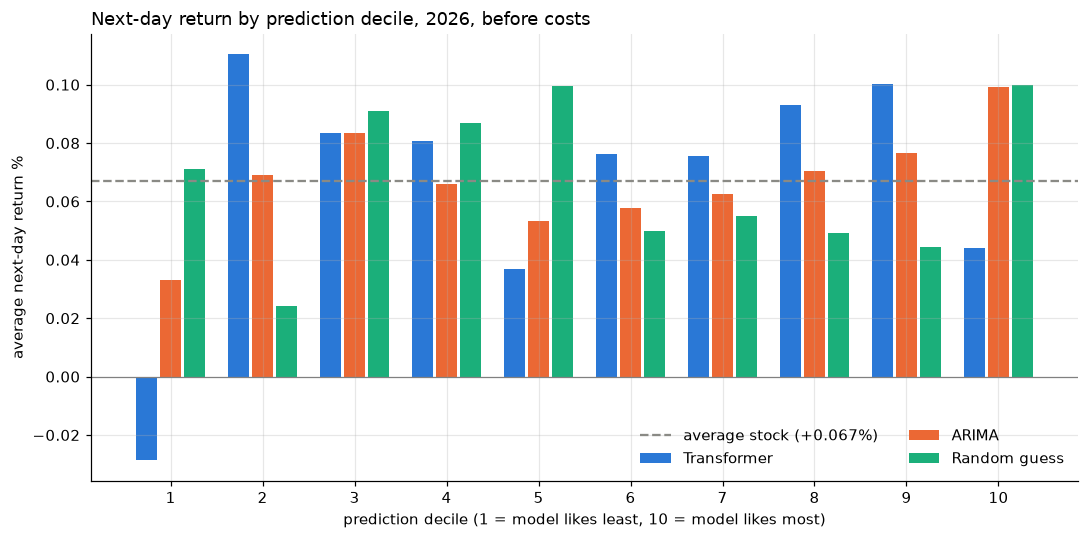

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, 11)
width = 0.26
for k, name in enumerate(preds):
    ax.bar(x + (k - 1) * width, deciles[name].iloc[:10], width=width * 0.9, color=COLORS[name], label=name)
avg = deciles.loc["average stock"].iloc[0]
ax.axhline(avg, color=COLORS[MARKET], ls="--", lw=1.5, label=f"average stock ({avg:+.3f}%)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(x, [f"{d}" for d in x])
ax.set_xlabel("prediction decile (1 = model likes least, 10 = model likes most)")
ax.set_ylabel("average next-day return %")
ax.set_title("Next-day return by prediction decile, 2026, before costs", loc="left")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

**Same comparison, relative to the average stock on the same day.** Much of the ± above is the whole market moving
up or down together, which moves every decile alike. Subtracting each day's average stock removes that and gives a fairer test:
a decile is only clearly better or worse than average when its ± range does not include 0.

In [13]:
excess, excess_margin = {}, {}
for name, df in preds.items():
    daily = decile_daily(df)
    ex = 100 * daily.sub(df[df["tradable"]].groupby("date")["ret"].mean(), axis=0)
    excess[name] = ex.mean().set_axis(LABELS)
    excess_margin[name] = (1.96 * ex.std() / np.sqrt(len(ex))).set_axis(LABELS)
excess, excess_margin = pd.DataFrame(excess), pd.DataFrame(excess_margin)

print("Next-day return % minus the average stock that day, ± 95% margin of error (* = range excludes 0)")
(excess.map(lambda v: f"{v:+.3f}") + " ± " + excess_margin.map(lambda v: f"{v:.3f}")
 + np.where(excess.abs() > excess_margin, " *", ""))

Next-day return % minus the average stock that day, ± 95% margin of error (* = range excludes 0)


,Transformer,ARIMA,Random guess
decile 1 (likes least),-0.096 ± 0.202,-0.034 ± 0.107,+0.004 ± 0.046
decile 2,+0.043 ± 0.096,+0.002 ± 0.049,-0.043 ± 0.040 *
decile 3,+0.016 ± 0.064,+0.016 ± 0.047,+0.024 ± 0.041
decile 4,+0.014 ± 0.052,-0.001 ± 0.067,+0.020 ± 0.044
decile 5,-0.030 ± 0.051,-0.014 ± 0.075,+0.032 ± 0.044
decile 6,+0.009 ± 0.064,-0.009 ± 0.065,-0.017 ± 0.043
decile 7,+0.008 ± 0.068,-0.005 ± 0.049,-0.012 ± 0.044
decile 8,+0.026 ± 0.069,+0.003 ± 0.045,-0.018 ± 0.041
decile 9,+0.033 ± 0.076,+0.010 ± 0.059,-0.023 ± 0.044
decile 10 (likes most),-0.023 ± 0.119,+0.032 ± 0.143,+0.033 ± 0.044


## Caveats
- **One period.** About 200 trading days in a single year. A strategy that wins here can lose in another year.
- **Survivorship bias.** Only stocks that still exist in late 2026 are included, which flatters every strategy, including the market line.
- **Execution.** Buying exactly at the close of the day the prediction is made is optimistic. Real orders also move the price, especially in small stocks.
- **Costs.** Change `COST_BPS` at the top to see how sensitive the results are. Strategies that trade more are hit harder.